# Phase 0 + Phase 1: validation protocol and a baseline MLP

**Phase 0** fixes the validation protocol that every later experiment uses: 5 folds over the labelled rows, stratified on class × group,
and one set of metrics.

**Phase 1** trains a plain MLP on the 768 main features (`E`) only. No supplementary features, no unlabelled rows, and no use of the deformation flag.
It compares three losses for the label imbalance: plain cross-entropy, class-weighted cross-entropy and logit-adjusted cross-entropy.
The best one becomes the baseline that later phases must beat.

Background: `eda_deformed.ipynb`. Shared code: `ie643/` (`data.py`, `cv.py`, `mlp.py`). The folds are created by `scripts/make_folds.py`.

**Runtime:** about 10 minutes on CPU (Sections 3 and 4 train 45 small networks each).

**Contents**
1. Setup
2. Phase 0: the validation protocol
3. Phase 1a: how much does the MLP overfit, and how much regularization?
4. Phase 1b: three losses for the label imbalance
5. The final baseline model and a submission file
6. Summary

## 1. Setup

In [1]:
import json
import time
from dataclasses import asdict, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.linear_model import RidgeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from ie643 import cv, data, mlp
from ie643.data import N_CLASSES

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]          # fixed colour per config/loss, in order
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.precision", 3)
print("torch", torch.__version__, "| CPU threads", torch.get_num_threads())

d = data.load()
groups, fold = cv.load_folds(d.train_id)
lab = d.labelled
X, y, g, f = d.E[lab], d.y[lab], groups[lab], fold[lab]     # labelled rows only
print("labelled rows:", len(y))

torch 2.14.1+cpu | CPU threads 10


labelled rows: 1284


## 2. Phase 0: the validation protocol

**Groups.** Every training row belongs to one of three groups (from `eda_deformed.ipynb`):
- `clean`: `is_deformed = 0`;
- `far`: deformed rows in the separate far group (Section 3.1 of the EDA), which are the hardest to classify;
- `deformed`: every other deformed row.

**Folds.** The 1284 labelled rows are split into 5 folds, stratified on **class × group**. Each fold therefore has the same class mix and the same
clean / deformed / far mix as the whole training set, which (EDA Section 6) is also the test set's mix. The assignment is saved in
`folds/cv_folds_v1.json` and loaded from there. The 792 unlabelled rows get fold `-1`: later phases may train on them, but they are never scored.

**Metrics,** computed on each validation fold and averaged:
- **balanced accuracy** (mean recall over the 11 classes): the **main metric**, our stand-in for the competition's hidden-weight accuracy;
- plain accuracy;
- accuracy within each group (clean, deformed, far).

In [2]:
# The saved file must match what the code produces
assert (cv.assign_groups(d.E, d.deformed) == groups).all()
assert (cv.make_folds(d.y, groups) == fold).all()
print("folds/cv_folds_v1.json matches ie643/cv.py")

by_group = pd.crosstab(f, g, margins=True, margins_name="total")
by_group.index.name, by_group.columns.name = "fold", None
display(by_group)
by_class = pd.crosstab(f, y)
by_class.index.name, by_class.columns.name = "fold", "class"
display(by_class)

folds/cv_folds_v1.json matches ie643/cv.py


C:\Users\Admin\.antigravity\IE643_Programming_Challenge\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


,clean,deformed,far,total
fold,,,,
0,26,202,29,257
1,28,201,28,257
2,28,200,29,257
3,28,199,30,257
4,26,200,30,256
total,136,1002,146,1284


class,0,1,2,3,4,5,6,7,8,9,10
fold,,,,,,,,,,,
0,90,9,10,18,15,23,28,19,10,27,8
1,90,9,9,18,15,23,28,19,11,27,8
2,89,9,10,20,15,23,27,20,10,27,7
3,90,10,10,17,14,24,29,20,10,26,7
4,91,9,9,18,15,22,29,19,9,25,10


**Reference: the linear probe from the EDA, on these folds.** This is the number the MLP has to beat.

In [3]:
def ridge_cv(X, y, g, f, alpha=100.0):
    rows = []
    for k in range(cv.N_FOLDS):
        tr, va = f != k, f == k
        p = make_pipeline(StandardScaler(), RidgeClassifier(alpha=alpha)).fit(X[tr], y[tr]).predict(X[va])
        rows.append(cv.evaluate(y[va], p, g[va]))
    return pd.DataFrame(rows)

def summarize(metrics, by="config"):
    cols = ["balanced accuracy", "accuracy", "accuracy: clean", "accuracy: deformed", "accuracy: far"]
    mean = metrics.groupby(by, sort=False)[cols].mean()
    mean["balanced accuracy, std over runs"] = metrics.groupby(by, sort=False)["balanced accuracy"].std()
    return mean

ridge = ridge_cv(X, y, g, f).assign(config="linear probe (ridge)")
display(summarize(ridge))

,balanced accuracy,accuracy,accuracy: clean,accuracy: deformed,accuracy: far,"balanced accuracy, std over runs"
config,,,,,,
linear probe (ridge),0.632,0.775,0.928,0.776,0.624,0.034


**What this shows.**
- **The folds are well balanced.** Each holds 256–257 labelled rows: 26–28 clean, 199–202 deformed and 28–30 far-group rows. Every class appears in every fold (class 10, the smallest, has 7–10 rows per fold).
- The scikit-learn warning is expected. Some class × group cells have fewer than 5 rows (clean class 8 has 3), so they cannot appear in every fold.
- **Reference to beat:** the linear probe scores **0.632** balanced accuracy and 0.775 accuracy on these folds (clean 0.928, deformed 0.776, far 0.624).
- **Noise level:** balanced accuracy varies by **0.034** (std) from fold to fold. A difference of about 0.02 between two single-seed settings is therefore noise. Section 4 uses 3 seeds and run-by-run comparisons for that reason.

## 3. Phase 1a: how much does the MLP overfit, and how much regularization?

**Model.** `standardize → dropout(input) → [Linear → GELU → Dropout] × hidden layers → Linear(11)`.
The standardization statistics are computed on the training part only and stored inside the model.

**Training.** AdamW, batch size 64, learning rate 1e-3 with cosine decay to 0, a fixed number of epochs (no early stopping, so the
validation fold is never used to pick a stopping point), plain cross-entropy.

**Six settings, one seed, the same 5 folds.** A pilot with setting A and 150 epochs scored no better than 40 epochs (balanced accuracy 0.655 vs 0.662), so every setting here uses 40.

In [4]:
SWEEP = {
    "A  512-256, dropout .3, input .1, wd .01": mlp.Config(epochs=40),
    "B  512-256, dropout .5, input .2, wd .05": mlp.Config(epochs=40, dropout=0.5, input_dropout=0.2, weight_decay=0.05),
    "C  256, dropout .5, input .2, wd .05": mlp.Config(epochs=40, dropout=0.5, input_dropout=0.2, weight_decay=0.05, hidden=(256,)),
    "D  512-256, dropout .5, input .4, wd .1": mlp.Config(epochs=40, dropout=0.5, input_dropout=0.4, weight_decay=0.1),
    "E  1024-512, dropout .5, input .2, wd .05": mlp.Config(epochs=40, dropout=0.5, input_dropout=0.2, weight_decay=0.05, hidden=(1024, 512)),
    "F  as B, lr 3e-4": mlp.Config(epochs=40, dropout=0.5, input_dropout=0.2, weight_decay=0.05, lr=3e-4),
}
sweep_metrics, sweep_hist = [], {}
t0 = time.time()
for name, cfg in SWEEP.items():
    m, h, _ = mlp.run_cv(X, y, g, f, cfg, seeds=(0,))
    sweep_metrics.append(m.assign(config=name))
    sweep_hist[name] = h.groupby("epoch")[["train loss", "val loss", "val balanced accuracy"]].mean()
sweep_metrics = pd.concat(sweep_metrics)
print(f"{len(sweep_metrics)} runs in {time.time() - t0:.0f} s")
display(summarize(pd.concat([ridge, sweep_metrics])))

30 runs in 386 s


,balanced accuracy,accuracy,accuracy: clean,accuracy: deformed,accuracy: far,"balanced accuracy, std over runs"
config,,,,,,
linear probe (ridge),0.632,0.775,0.928,0.776,0.624,0.034
"A 512-256, dropout .3, input .1, wd .01",0.662,0.774,0.921,0.778,0.610,0.038
"B 512-256, dropout .5, input .2, wd .05",0.664,0.782,0.927,0.785,0.624,0.026
"C 256, dropout .5, input .2, wd .05",0.660,0.778,0.927,0.783,0.611,0.034
"D 512-256, dropout .5, input .4, wd .1",0.652,0.772,0.935,0.777,0.583,0.036
"E 1024-512, dropout .5, input .2, wd .05",0.659,0.772,0.942,0.777,0.576,0.031
"F as B, lr 3e-4",0.652,0.774,0.927,0.779,0.596,0.034


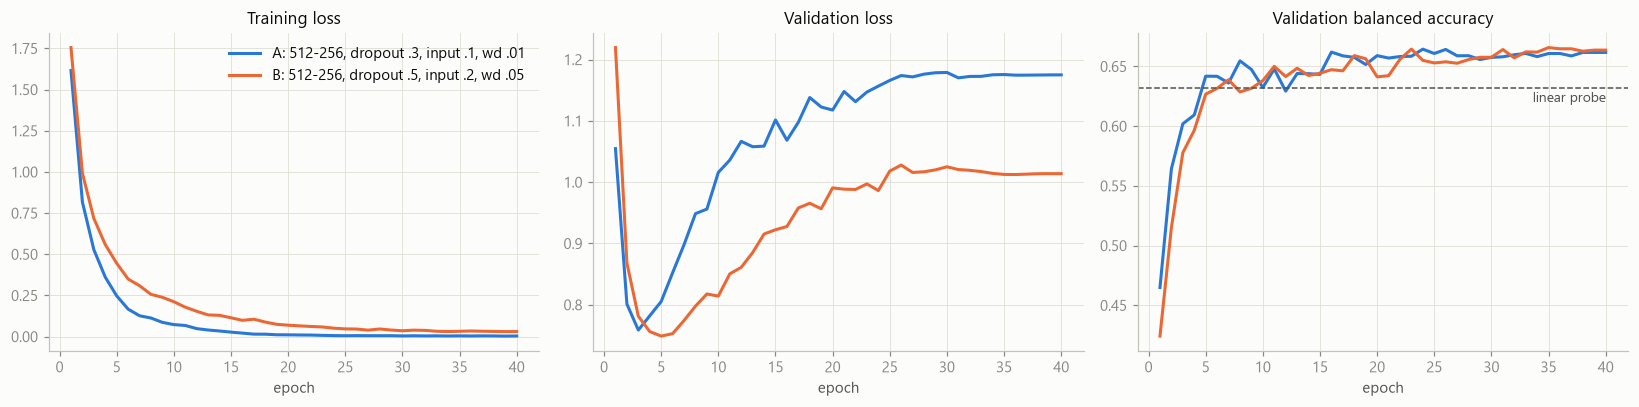

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for (name, color) in zip(["A  512-256, dropout .3, input .1, wd .01", "B  512-256, dropout .5, input .2, wd .05"], SERIES):
    c = sweep_hist[name]
    label = name.split("  ")[0] + ": " + name.split("  ")[1]
    ax[0].plot(c.index, c["train loss"], color=color, linewidth=2, label=label)
    ax[1].plot(c.index, c["val loss"], color=color, linewidth=2, label=label)
    ax[2].plot(c.index, c["val balanced accuracy"], color=color, linewidth=2, label=label)
ax[2].axhline(summarize(ridge)["balanced accuracy"].iloc[0], color=INK2, linestyle="--", linewidth=1)
ax[2].text(40, summarize(ridge)["balanced accuracy"].iloc[0] - 0.012, "linear probe", color=INK2, fontsize=9, ha="right")
ax[0].set(title="Training loss", xlabel="epoch")
ax[1].set(title="Validation loss", xlabel="epoch")
ax[2].set(title="Validation balanced accuracy", xlabel="epoch")
ax[0].legend()
plt.tight_layout()
plt.show()

**What this shows.**
- **The MLP overfits quickly.** Training loss falls to almost 0 within 10–15 epochs (1027 training rows, 768 features). Validation loss bottoms out at epoch 3–5 and then rises.
- **Validation balanced accuracy still climbs to about 0.66 and then stays flat.** The ranking of classes stays right while the probabilities become overconfident. Stronger regularization (B) roughly halves the rise in validation loss but does not change accuracy.
- **All six settings land between 0.652 and 0.664**, with a fold-to-fold std of 0.026–0.038, so the differences between them are noise. The MLP beats the linear probe by about 0.03 balanced accuracy, at the same plain accuracy (0.772–0.782 vs 0.775).

**Conclusion.** With only the labelled rows and only `E`, the bottleneck is the **information** available, not model capacity or regularization. Bigger gains have to come from new signal: the supplementary features (Phase 3) and the unlabelled rows (Phase 4).
**Setting B** is kept as the baseline: it has the best accuracy and far-group accuracy and the smallest spread.

The overconfidence (rising validation loss) matters later. Distillation and pseudo-labelling need well-calibrated probabilities, so we will check calibration there.

## 4. Phase 1b: three losses for the label imbalance

With setting B fixed, we change only the loss. `n_c` is the number of training rows in class `c`, and `K = 11`.
- **Cross-entropy (`ce`)**: every row counts equally, so class 0 (35% of rows) dominates.
- **Class-weighted cross-entropy (`weighted_ce`)**: row weight `n / (K · n_c)`, so every class contributes equally to the loss.
- **Logit-adjusted cross-entropy (`logit_adjusted`)**: train on `logits + τ · log(prior_c)` with τ = 1, and predict with the raw logits.
  This is the Bayes-consistent loss for balanced error (Menon et al., 2021).

**3 seeds × 5 folds = 15 runs per loss.** Every loss sees the same folds and seeds, so the differences can be compared run by run.

In [6]:
BASE = SWEEP["B  512-256, dropout .5, input .2, wd .05"]
SEEDS = (0, 1, 2)
loss_metrics, loss_oof = [], {}
t0 = time.time()
for loss in mlp.LOSSES:
    cfg = replace(BASE, loss=loss)
    m, _, oof = mlp.run_cv(X, y, g, f, cfg, seeds=SEEDS)
    loss_metrics.append(m)
    loss_oof[cfg.name()] = oof
loss_metrics = pd.concat(loss_metrics)
print(f"{len(loss_metrics)} runs in {time.time() - t0:.0f} s")
display(summarize(pd.concat([ridge, loss_metrics])))

45 runs in 1190 s


,balanced accuracy,accuracy,accuracy: clean,accuracy: deformed,accuracy: far,"balanced accuracy, std over runs"
config,,,,,,
linear probe (ridge),0.632,0.775,0.928,0.776,0.624,0.034
ce,0.657,0.775,0.928,0.778,0.608,0.026
weighted_ce,0.679,0.775,0.935,0.778,0.601,0.028
logit_adjusted (tau=1),0.682,0.775,0.927,0.781,0.592,0.032


In [7]:
# Paired differences against plain cross-entropy (same seed and fold)
piv = loss_metrics.pivot_table(index=["seed", "fold"], columns="config", values=["balanced accuracy", "accuracy"])
rows = []
for name in loss_oof:
    if name == "ce":
        continue
    for metric in ["balanced accuracy", "accuracy"]:
        diff = piv[(metric, name)] - piv[(metric, "ce")]
        rows.append({"loss": name, "metric": metric, "mean difference vs ce": diff.mean(),
                     "std": diff.std(), "runs where it is higher": f"{(diff > 0).sum()}/{len(diff)}"})
display(pd.DataFrame(rows))

,loss,metric,mean difference vs ce,std,runs where it is higher
0,weighted_ce,balanced accuracy,2.195e-02,0.018,12/15
1,weighted_ce,accuracy,7.093e-06,0.014,7/15
2,logit_adjusted (tau=1),balanced accuracy,2.570e-02,0.017,14/15
3,logit_adjusted (tau=1),accuracy,5.239e-04,0.012,5/15


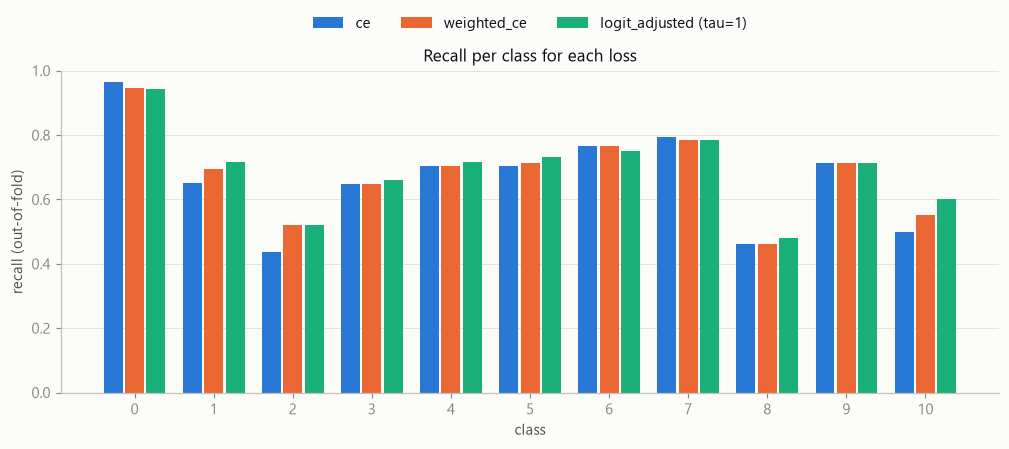

,0,1,2,3,4,5,6,7,8,9,10
share of labelled rows,0.35,0.04,0.04,0.07,0.06,0.09,0.11,0.08,0.04,0.10,0.03
ce,0.96,0.65,0.44,0.65,0.70,0.70,0.77,0.79,0.46,0.71,0.50
weighted_ce,0.95,0.70,0.52,0.65,0.70,0.71,0.77,0.78,0.46,0.71,0.55
logit_adjusted (tau=1),0.94,0.72,0.52,0.66,0.72,0.73,0.75,0.78,0.48,0.71,0.60


In [8]:
# Per-class recall from the out-of-fold predictions (probabilities averaged over the 3 seeds)
recall = pd.DataFrame({name: cv.per_class_recall(y, p.argmax(1)) for name, p in loss_oof.items()})
recall.index.name = "class"
train_share = pd.Series(np.bincount(y, minlength=N_CLASSES) / len(y), name="share of labelled rows")

fig, ax = plt.subplots(figsize=(11, 3.8))
w = 0.27
for i, (name, color) in enumerate(zip(recall.columns, SERIES)):
    ax.bar(recall.index + (i - 1) * w, recall[name], width=w - 0.03, color=color, label=name)
ax.set_xticks(recall.index)
ax.set(xlabel="class", ylabel="recall (out-of-fold)", title="Recall per class for each loss", ylim=(0, 1))
ax.grid(axis="x", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncols=3)
plt.show()
display(pd.concat([train_share, recall], axis=1).T.style.format("{:.2f}"))

**What this shows.**
- Balanced accuracy: **ce 0.657, weighted_ce 0.679, logit_adjusted 0.682**. Plain accuracy is 0.775 for all three.
- Run by run, logit adjustment beats plain cross-entropy by **+0.026** balanced accuracy in **14 of 15** runs. Class weighting gains +0.022, in 12 of 15. Neither changes plain accuracy.
- **The gain comes from the rare classes**: recall for class 10 rises from 0.50 to 0.60, class 2 from 0.44 to 0.52 and class 1 from 0.65 to 0.72. The cost is small: class 0 recall goes from 0.96 to 0.94.
- Classes 2 and 8 (recall about 0.5) and class 10 (0.6) remain the hardest.
- Far-group accuracy is slightly lower with logit adjustment (0.592 vs 0.608). That is within noise, but worth watching.

**Decision:** use **logit-adjusted cross-entropy** (τ = 1).

## 5. The final baseline model and a submission file

The chosen loss is trained on **all 1284 labelled rows** with 5 seeds. The test prediction averages the 5 models' probabilities.
The weights are saved to `checkpoints/phase1_baseline/` and the submission to `submissions/`. Both folders are git-ignored:
the weights are kept for the final Drive hand-in, and the CSV is uploaded to Kaggle by hand.

In [9]:
CHOSEN_LOSS = "logit_adjusted"      # picked in Section 4
final_cfg = replace(BASE, loss=CHOSEN_LOSS)
FINAL_SEEDS = (0, 1, 2, 3, 4)
print("final config:", final_cfg)

models = mlp.fit_ensemble(X, y, final_cfg, seeds=FINAL_SEEDS)
proba_test = mlp.ensemble_proba(models, d.F)
pred_test = proba_test.argmax(1)

ckpt_dir = Path("checkpoints/phase1_baseline")
ckpt_dir.mkdir(parents=True, exist_ok=True)
for s, m in zip(FINAL_SEEDS, models):
    torch.save(m.state_dict(), ckpt_dir / f"seed{s}.pt")
(ckpt_dir / "config.json").write_text(json.dumps({**asdict(final_cfg), "seeds": FINAL_SEEDS}, indent=1))
print("saved", len(models), "models to", ckpt_dir)

final config: Config(hidden=(512, 256), dropout=0.5, input_dropout=0.2, lr=0.001, weight_decay=0.05, epochs=40, batch_size=64, loss='logit_adjusted', tau=1.0)


saved 5 models to checkpoints\phase1_baseline


In [10]:
sub = pd.DataFrame({"ID": d.test_id.astype(int), "Label": pred_test.astype(int)})
assert len(sub) == 490 and sub["ID"].is_unique and sub["Label"].between(0, N_CLASSES - 1).all()
Path("submissions").mkdir(exist_ok=True)
sub_path = Path("submissions") / f"phase1_mlp_{CHOSEN_LOSS}.csv"
sub.to_csv(sub_path, index=False)
print("wrote", sub_path, "-", len(sub), "rows")
print(sub.head(3).to_string(index=False))

far_test = cv.assign_groups(d.E, d.deformed, d.F)
compare = pd.DataFrame({
    "labelled train": np.bincount(y, minlength=N_CLASSES) / len(y),
    "test predictions": np.bincount(pred_test, minlength=N_CLASSES) / len(pred_test),
})
compare.index.name = "class"
display(compare.T.style.format("{:.1%}"))
print(f"mean top-class probability on test: {proba_test.max(1).mean():.2f} "
      f"(far group {proba_test[far_test].max(1).mean():.2f}, rest {proba_test[~far_test].max(1).mean():.2f})")

wrote submissions\phase1_mlp_logit_adjusted.csv - 490 rows
 ID  Label
  1      5
  2      8
  3      3


class,0,1,2,3,4,5,6,7,8,9,10
labelled train,35.0%,3.6%,3.7%,7.1%,5.8%,9.0%,11.0%,7.6%,3.9%,10.3%,3.1%
test predictions,12.2%,5.9%,5.7%,9.6%,9.4%,11.8%,11.4%,10.8%,7.1%,9.2%,6.7%


mean top-class probability on test: 0.85 (far group 0.59, rest 0.88)


**What this shows.**
- Five models were trained on all 1284 labelled rows. The submission file passed the format checks (490 rows, unique integer IDs, labels 0–10).
- **The test predictions have a very different class mix from the training labels**: class 0 is only **12.2%** of test predictions vs **35.0%** of labelled training rows, and every class gets between 5.7% and 12.2%.
- The models are much less confident on the far group (mean top-class probability 0.59 vs 0.88 elsewhere), which matches the cross-validation result that these rows are the hardest.

Section 5.1 checks whether the class-mix difference is real.

### 5.1 Is the test set's class mix the same as the training set's?

The test predictions above contain far less class 0 than the training labels. Either the model behaves differently on test, or the test set has a
different class mix (a *label shift*). The check below compares the **same kind of model** on rows whose mix we know (out-of-fold
predictions, which follow the training mix) and on the test rows. The unadjusted linear probe is included as a second, independent model.

class,0,1,2,3,4,5,6,7,8,9,10
labelled train (true labels),35.0%,3.6%,3.7%,7.1%,5.8%,9.0%,11.0%,7.6%,3.9%,10.3%,3.1%
"MLP, out-of-fold predictions",35.1%,3.9%,3.4%,6.6%,5.9%,9.7%,11.4%,7.5%,3.8%,9.5%,3.1%
"MLP, test predictions",12.2%,5.9%,5.7%,9.6%,9.4%,11.8%,11.4%,10.8%,7.1%,9.2%,6.7%
"linear probe, out-of-fold predictions",40.3%,1.9%,1.6%,6.6%,5.5%,9.7%,12.0%,7.6%,2.0%,10.5%,2.0%
"linear probe, test predictions",21.6%,2.9%,1.8%,9.6%,7.1%,14.7%,12.7%,12.4%,3.9%,9.4%,3.9%


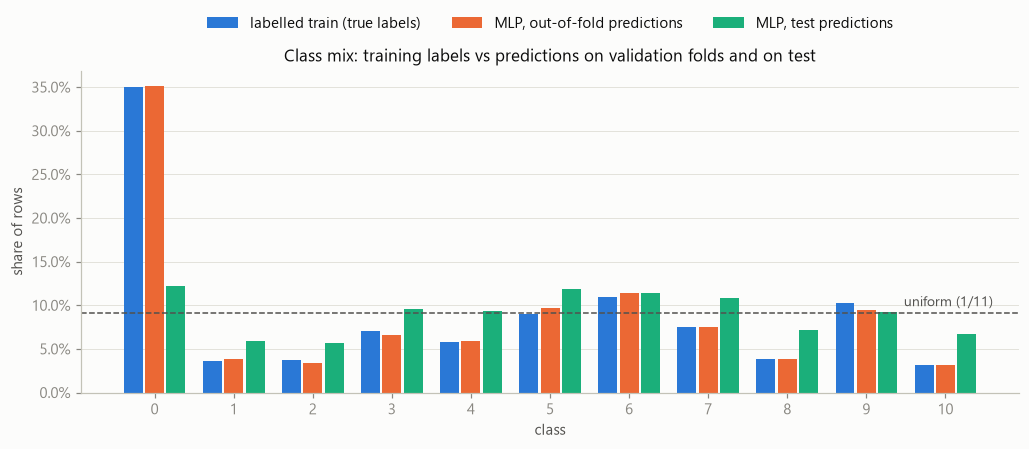

distance (total variation) of the MLP test predictions to uniform: 0.109, to the training mix: 0.239


In [11]:
share = lambda p: np.bincount(p, minlength=N_CLASSES) / len(p)

ridge_oof = np.zeros(len(y), dtype=int)
for k in range(cv.N_FOLDS):
    tr, va = f != k, f == k
    ridge_oof[va] = make_pipeline(StandardScaler(), RidgeClassifier(alpha=100.0)).fit(X[tr], y[tr]).predict(X[va])
ridge_test = make_pipeline(StandardScaler(), RidgeClassifier(alpha=100.0)).fit(X, y).predict(d.F)

mix = pd.DataFrame({
    "labelled train (true labels)": share(y),
    "MLP, out-of-fold predictions": share(loss_oof[final_cfg.name()].argmax(1)),
    "MLP, test predictions": share(pred_test),
    "linear probe, out-of-fold predictions": share(ridge_oof),
    "linear probe, test predictions": share(ridge_test),
})
mix.index.name = "class"
display(mix.T.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(11, 3.8))
w = 0.27
cols = ["labelled train (true labels)", "MLP, out-of-fold predictions", "MLP, test predictions"]
for i, (name, color) in enumerate(zip(cols, SERIES)):
    ax.bar(mix.index + (i - 1) * w, mix[name], width=w - 0.03, color=color, label=name)
ax.axhline(1 / N_CLASSES, color=INK2, linestyle="--", linewidth=1)
ax.text(10.6, 1 / N_CLASSES + 0.008, "uniform (1/11)", color=INK2, fontsize=9, ha="right")
ax.set_xticks(mix.index)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set(xlabel="class", ylabel="share of rows", title="Class mix: training labels vs predictions on validation folds and on test")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncols=3)
plt.show()

tv = lambda p, q: 0.5 * np.abs(p - q).sum()
uniform = np.full(N_CLASSES, 1 / N_CLASSES)
print(f"distance (total variation) of the MLP test predictions to uniform: {tv(share(pred_test), uniform):.3f}, "
      f"to the training mix: {tv(share(pred_test), share(y)):.3f}")

**What this shows.**
- **On the validation folds the MLP reproduces the training mix almost exactly** (class 0: 35.1% predicted vs 35.0% true). So the model does not over- or under-predict class 0 on data with the training mix.
- **On test, the same kind of model predicts class 0 for only 12.2% of rows.** The independent, unadjusted linear probe shows the same drop: 40.3% on validation folds, 21.6% on test.
- The MLP's test predictions are much closer to uniform (total variation distance 0.109) than to the training mix (0.239). The rare classes 1, 2, 8 and 10 roughly double their share.

**Conclusion: the test set very likely has a different class mix from training, with far fewer class-0 rows (a label shift).**
- The EDA found almost no difference in the deformation mix (Section 6 there). The adversarial AUC of 0.576 is consistent with a mild label shift.
- The exact test mix cannot be read off the predictions, because they contain errors. A **near-balanced test set** is a plausible guess, not a proven one.

**Implications**
- **Balanced accuracy is the right number to track.** On a balanced test set, accuracy and balanced accuracy coincide.
- **Models must not carry the training prior into test.** Plain cross-entropy pushes towards class 0, and logit adjustment is the right default.
- Possible later improvements:
  - estimate the test prior (EM re-weighting of calibrated probabilities, Saerens et al. 2002) and correct for it;
  - tune τ above 1.
  The Kaggle score will show whether either helps.

## 6. Summary

**Phase 0** fixed the protocol: `folds/cv_folds_v1.json` (5 folds, stratified on class × group), with balanced accuracy as the main metric and accuracy reported per group.

**Phase 1 baseline:** MLP 768 → 512 → 256 → 11 (dropout 0.5, input dropout 0.2, AdamW with weight decay 0.05, 40 epochs with cosine decay), trained with **logit-adjusted cross-entropy**.

| | CV balanced accuracy | CV accuracy | clean / deformed / far |
|---|---|---|---|
| Linear probe (reference) | 0.632 | 0.775 | 0.928 / 0.776 / 0.624 |
| MLP, plain cross-entropy | 0.657 | 0.775 | 0.928 / 0.778 / 0.608 |
| **MLP, logit-adjusted (baseline)** | **0.682** | **0.775** | **0.927 / 0.781 / 0.592** |

Submission: `submissions/phase1_mlp_logit_adjusted.csv`. Weights: `checkpoints/phase1_baseline/`.

**What we learned**
1. **Capacity and regularization are not the bottleneck.** Six settings perform the same. The next gains must come from new information: Phase 3 (a teacher on the supplementary features) and Phase 4 (the unlabelled rows).
2. **The networks overfit within a few epochs and become overconfident.** Calibrate before using their probabilities for distillation or pseudo-labels.
3. **Logit adjustment raises balanced accuracy by about 0.03 without costing plain accuracy**, because it lifts recall on the rare classes.
4. **The test set very likely has far fewer class-0 rows than training, possibly close to balanced** (Section 5.1). Balanced accuracy is the right metric to track, and correcting for the class prior matters.
5. **The far group is still the weakest part** (0.59 accuracy).

**Next**
- Upload the submission and record the Kaggle score in `docs/experiment_log.md`. Comparing it with CV balanced accuracy (0.682) and plain accuracy (0.775) shows which one the leaderboard follows.
- Then Phase 3. The Phase 2 ideas (using the deformation flag) had no measurable effect on the linear probe in the EDA, so they are lower priority.